THIS IS FOR RUL CALCULATION(REMAINING USEFUL LIFE)

Our current ai4i2020.csv is excellent for classification, but it is not a proper run-to-failure time-series dataset.
We should not create an artificial RUL column from AI4I.
For this part, we'll use the NASA C-MAPSS Turbofan Engine Degradation Dataset, a standard benchmark for RUL modelling.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


Define C-MAPSS columns

In [3]:
columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

print(columns)
print("\nTotal columns:", len(columns))

['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']

Total columns: 26


Load all three FD001 files

In [4]:
train_path = "../data/raw/cmapss/train_FD001.txt"
test_path = "../data/raw/cmapss/test_FD001.txt"
rul_path = "../data/raw/cmapss/RUL_FD001.txt"

train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None,
    names=columns
)

rul_df = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
print("RUL shape  :", rul_df.shape)

Train shape: (20631, 26)
Test shape : (13096, 26)
RUL shape  : (100, 1)


Dataset quality check

In [5]:
print("TRAIN DATA")
print("-------------------------")
print("Engines:", train_df["engine_id"].nunique())
print("Minimum cycle:", train_df["cycle"].min())
print("Maximum cycle:", train_df["cycle"].max())
print("Missing values:", train_df.isnull().sum().sum())
print("Duplicate rows:", train_df.duplicated().sum())

print("\nTEST DATA")
print("-------------------------")
print("Engines:", test_df["engine_id"].nunique())
print("Missing values:", test_df.isnull().sum().sum())
print("Duplicate rows:", test_df.duplicated().sum())

TRAIN DATA
-------------------------
Engines: 100
Minimum cycle: 1
Maximum cycle: 362
Missing values: 0
Duplicate rows: 0

TEST DATA
-------------------------
Engines: 100
Missing values: 0
Duplicate rows: 0


Check Engine 1

In [6]:
engine_1 = train_df[
    train_df["engine_id"] == 1
]

print("Engine 1 records:", len(engine_1))

engine_1.head()

Engine 1 records: 192


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [7]:
engine_1.tail()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
187,1,188,-0.0067,0.0003,100.0,518.67,643.75,1602.38,1422.78,14.62,...,519.79,2388.23,8117.69,8.5207,0.03,396,2388,100.0,38.51,22.9588
188,1,189,-0.0006,0.0002,100.0,518.67,644.18,1596.17,1428.01,14.62,...,519.58,2388.33,8117.51,8.5183,0.03,395,2388,100.0,38.48,23.1127
189,1,190,-0.0027,0.0001,100.0,518.67,643.64,1599.22,1425.95,14.62,...,520.04,2388.35,8112.58,8.5223,0.03,398,2388,100.0,38.49,23.0675
190,1,191,-0.0000,-0.0004,100.0,518.67,643.34,1602.36,1425.77,14.62,...,519.57,2388.30,8114.61,8.5174,0.03,394,2388,100.0,38.45,23.1295
191,1,192,0.0009,-0.0000,100.0,518.67,643.54,1601.41,1427.20,14.62,...,520.08,2388.32,8110.93,8.5113,0.03,396,2388,100.0,38.48,22.9649


Create the RUL target

In [8]:
max_cycles = (
    train_df
    .groupby("engine_id")["cycle"]
    .max()
    .reset_index()
)

max_cycles.columns = [
    "engine_id",
    "max_cycle"
]

train_df = train_df.merge(
    max_cycles,
    on="engine_id",
    how="left"
)

train_df["RUL"] = (
    train_df["max_cycle"]
    - train_df["cycle"]
)

train_df[
    ["engine_id", "cycle", "max_cycle", "RUL"]
].head(10)

,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


Verify Engine 1 RUL

In [9]:
train_df[
    train_df["engine_id"] == 1
][
    ["engine_id", "cycle", "max_cycle", "RUL"]
].tail(10)

,engine_id,cycle,max_cycle,RUL
182,1,183,192,9
183,1,184,192,8
184,1,185,192,7
185,1,186,192,6
186,1,187,192,5
187,1,188,192,4
188,1,189,192,3
189,1,190,192,2
190,1,191,192,1
191,1,192,192,0


RUL statistics

In [10]:
train_df["RUL"].describe()

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

Engine lifetime statistics

In [11]:
engine_lifetimes = (
    train_df
    .groupby("engine_id")["cycle"]
    .max()
)

engine_lifetimes.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

Check variation of every feature

In [12]:
candidate_features = (
    [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

feature_stats = pd.DataFrame({
    "Mean": train_df[candidate_features].mean(),
    "Std": train_df[candidate_features].std(),
    "Min": train_df[candidate_features].min(),
    "Max": train_df[candidate_features].max(),
    "Unique Values": train_df[candidate_features].nunique()
})

feature_stats

,Mean,Std,Min,Max,Unique Values
setting_1,-0.000009,2.187313e-03,-0.0087,0.0087,158
setting_2,0.000002,2.930621e-04,-0.0006,0.0006,13
setting_3,100.000000,0.000000e+00,100.0000,100.0000,1
sensor_1,518.670000,0.000000e+00,518.6700,518.6700,1
sensor_2,642.680934,5.000533e-01,641.2100,644.5300,310
sensor_3,1590.523119,6.131150e+00,1571.0400,1616.9100,3012
sensor_4,1408.933782,9.000605e+00,1382.2500,1441.4900,4051
sensor_5,14.620000,5.329200e-15,14.6200,14.6200,1
sensor_6,21.609803,1.388985e-03,21.6000,21.6100,2
sensor_7,553.367711,8.850923e-01,549.8500,556.0600,513


Automatically identify constant/near-constant features

In [13]:
constant_features = [
    col for col in candidate_features
    if train_df[col].nunique() <= 1
]

print("Constant features:")
print(constant_features)

Constant features:
['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


In [14]:
feature_variance = (
    train_df[candidate_features]
    .var()
    .sort_values()
)

feature_variance

sensor_1     0.000000e+00
setting_3    0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.203765e-35
sensor_5     2.840037e-29
setting_2    8.588541e-08
sensor_6     1.929279e-06
setting_1    4.784340e-06
sensor_15    1.406628e-03
sensor_8     5.038938e-03
sensor_13    5.172330e-03
sensor_21    1.171825e-02
sensor_20    3.266927e-02
sensor_11    7.133568e-02
sensor_2     2.500533e-01
sensor_12    5.439850e-01
sensor_7     7.833883e-01
sensor_17    2.398667e+00
sensor_3     3.759099e+01
sensor_4     8.101089e+01
sensor_14    3.639005e+02
sensor_9     4.876536e+02
dtype: float64

In [15]:
feature_variance = (
    train_df[candidate_features]
    .var()
    .sort_values()
)

feature_variance

sensor_1     0.000000e+00
setting_3    0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    1.203765e-35
sensor_5     2.840037e-29
setting_2    8.588541e-08
sensor_6     1.929279e-06
setting_1    4.784340e-06
sensor_15    1.406628e-03
sensor_8     5.038938e-03
sensor_13    5.172330e-03
sensor_21    1.171825e-02
sensor_20    3.266927e-02
sensor_11    7.133568e-02
sensor_2     2.500533e-01
sensor_12    5.439850e-01
sensor_7     7.833883e-01
sensor_17    2.398667e+00
sensor_3     3.759099e+01
sensor_4     8.101089e+01
sensor_14    3.639005e+02
sensor_9     4.876536e+02
dtype: float64

Check correlation with RUL

In [16]:
rul_correlations = (
    train_df[
        candidate_features + ["RUL"]
    ]
    .corr()["RUL"]
    .drop("RUL")
    .sort_values()
)

print(rul_correlations)

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
setting_1   -0.003198
setting_2   -0.001948
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
setting_3         NaN
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64


Correlation near -1
→ feature tends to increase as remaining life decreases

Correlation near +1
→ feature tends to decrease as remaining life decreases

Correlation near 0
→ weak linear relationship

Absolute correlation ranking

In [17]:
absolute_rul_correlation = (
    rul_correlations
    .abs()
    .sort_values(ascending=False)
)

absolute_rul_correlation

sensor_11    0.696228
sensor_4     0.678948
sensor_12    0.671983
sensor_7     0.657223
sensor_15    0.642667
sensor_21    0.635662
sensor_20    0.629428
sensor_2     0.606484
sensor_17    0.606154
sensor_3     0.584520
sensor_8     0.563968
sensor_13    0.562569
sensor_9     0.390102
sensor_14    0.306769
sensor_6     0.128348
setting_1    0.003198
setting_2    0.001948
setting_3         NaN
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64

Visualize several sensor trajectories

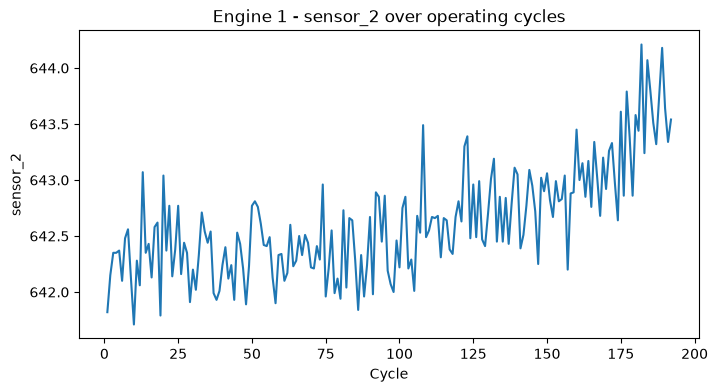

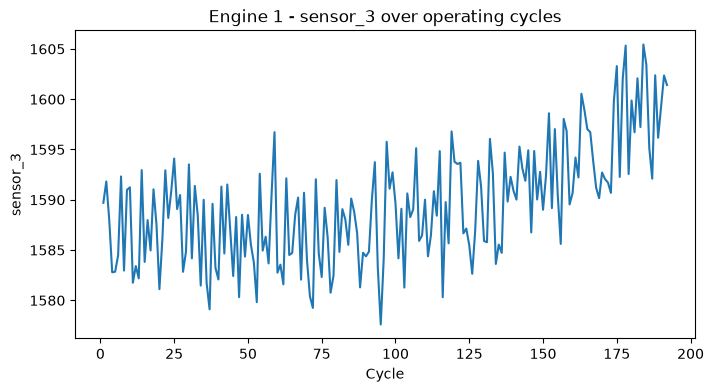

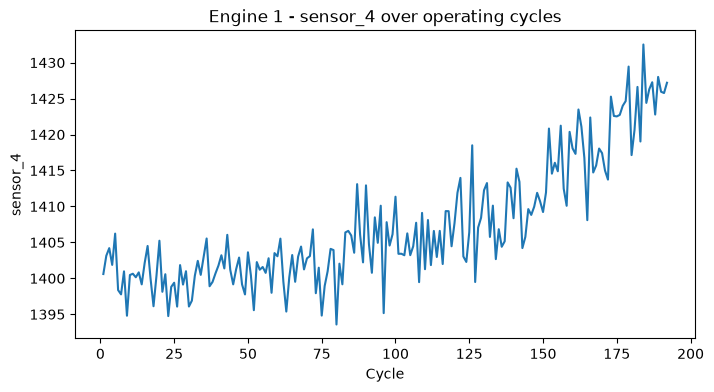

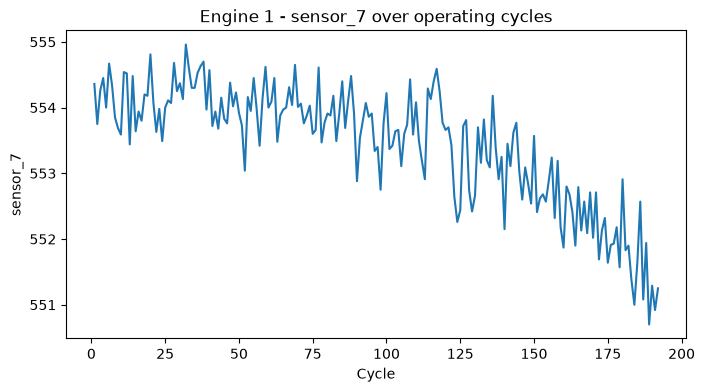

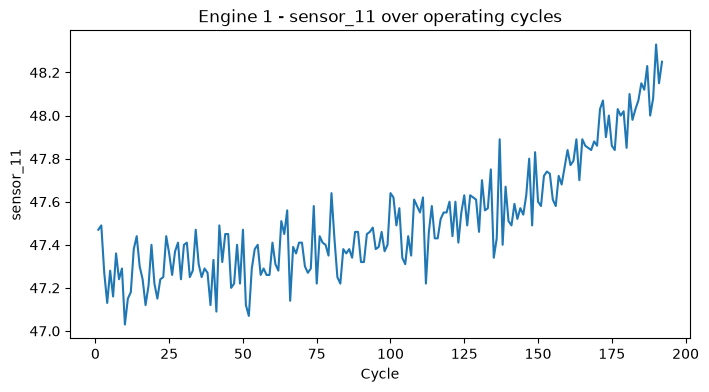

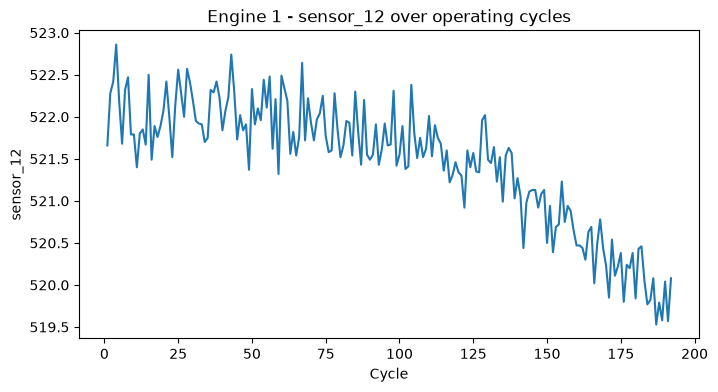

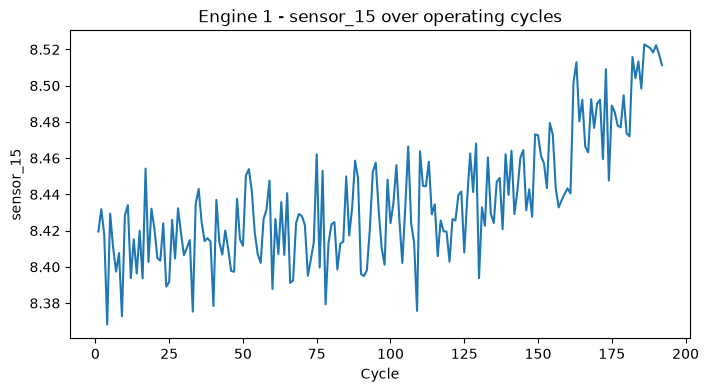

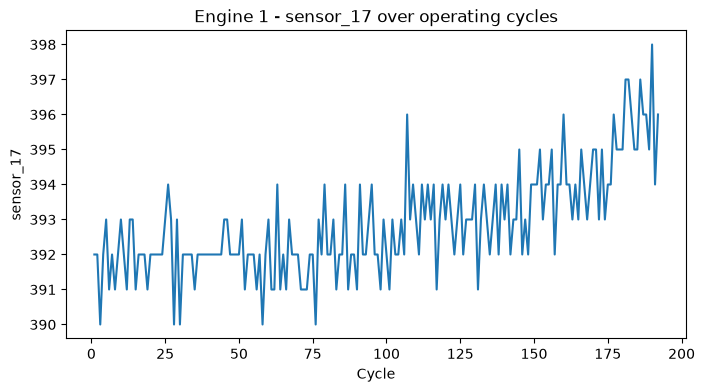

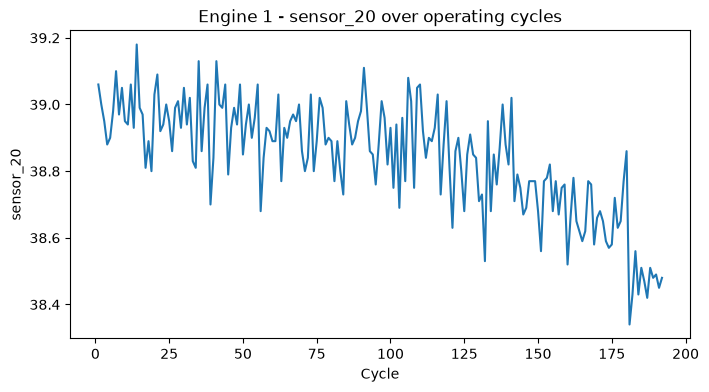

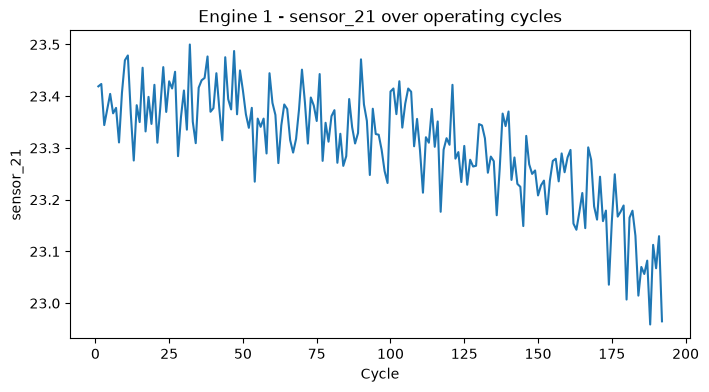

In [18]:
example_engine = train_df[
    train_df["engine_id"] == 1
]

sensors_to_plot = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

for sensor in sensors_to_plot:

    plt.figure(figsize=(8, 4))

    plt.plot(
        example_engine["cycle"],
        example_engine[sensor]
    )

    plt.xlabel("Cycle")
    plt.ylabel(sensor)
    plt.title(
        f"Engine 1 - {sensor} over operating cycles"
    )

    plt.show()

CAPPER RUL

In [19]:
RUL_CAP = 125

train_df["RUL_original"] = train_df["RUL"]

train_df["RUL_capped"] = (
    train_df["RUL"]
    .clip(upper=RUL_CAP)
)

train_df[
    [
        "engine_id",
        "cycle",
        "RUL_original",
        "RUL_capped"
    ]
].head()

,engine_id,cycle,RUL_original,RUL_capped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


In [20]:
train_df[
    ["RUL_original", "RUL_capped"]
].describe()

,RUL_original,RUL_capped
count,20631.000000,20631.000000
mean,107.807862,86.829286
std,68.880990,41.673699
min,0.000000,0.000000
25%,51.000000,51.000000
50%,103.000000,103.000000
75%,155.000000,125.000000
max,361.000000,125.000000


Compare original vs capped RUL

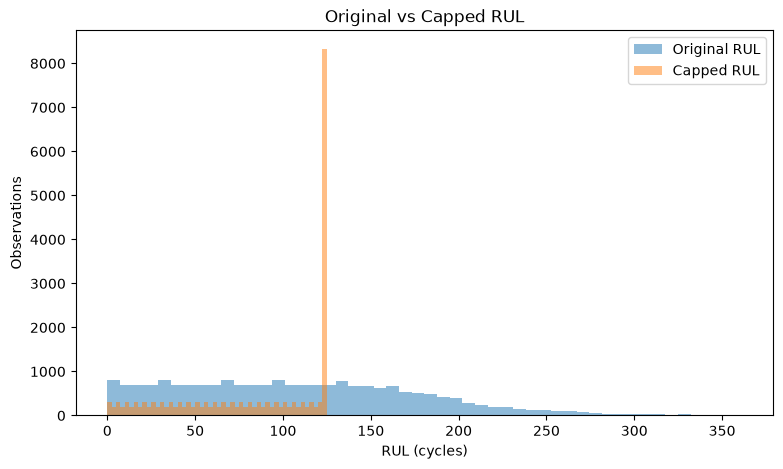

In [21]:
plt.figure(figsize=(9, 5))

plt.hist(
    train_df["RUL_original"],
    bins=50,
    alpha=0.5,
    label="Original RUL"
)

plt.hist(
    train_df["RUL_capped"],
    bins=50,
    alpha=0.5,
    label="Capped RUL"
)

plt.xlabel("RUL (cycles)")
plt.ylabel("Observations")
plt.title("Original vs Capped RUL")
plt.legend()

plt.show()

The spike at 125 is expected because all original RUL values greater than 125 are mapped to 125.

Remove the 7 constant features

setting_3
sensor_1
sensor_5
sensor_10
sensor_16
sensor_18
sensor_19

Create our feature set

In [22]:
constant_features = [
    "setting_3",
    "sensor_1",
    "sensor_5",
    "sensor_10",
    "sensor_16",
    "sensor_18",
    "sensor_19"
]

model_features = [
    "cycle",
    "setting_1",
    "setting_2",
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

print("Number of model features:", len(model_features))
print(model_features)

Number of model features: 18
['cycle', 'setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


Now create an engine-level validation split

This is very important.
We have 100 training engines. We can use approximately:
80 engines → training
20 engines → validation

but entire engines must remain together.

In [23]:
from sklearn.model_selection import train_test_split

engine_ids = train_df["engine_id"].unique()

train_engine_ids, val_engine_ids = train_test_split(
    engine_ids,
    test_size=0.20,
    random_state=42
)

train_data = train_df[
    train_df["engine_id"].isin(train_engine_ids)
].copy()

val_data = train_df[
    train_df["engine_id"].isin(val_engine_ids)
].copy()

print("Training engines:", len(train_engine_ids))
print("Validation engines:", len(val_engine_ids))

print("Training rows:", len(train_data))
print("Validation rows:", len(val_data))

Training engines: 80
Validation engines: 20
Training rows: 16561
Validation rows: 4070


Verify zero engine leakage

In [24]:
overlap = set(train_engine_ids).intersection(
    set(val_engine_ids)
)

print("Engine overlap:", overlap)

Engine overlap: set()


Prepare X and y
We'll use our capped RUL target:

In [25]:
X_train_rul = train_data[model_features].copy()
y_train_rul = train_data["RUL_capped"].copy()

X_val_rul = val_data[model_features].copy()
y_val_rul = val_data["RUL_capped"].copy()

print("X train:", X_train_rul.shape)
print("y train:", y_train_rul.shape)

print("X validation:", X_val_rul.shape)
print("y validation:", y_val_rul.shape)

X train: (16561, 18)
y train: (16561,)
X validation: (4070, 18)
y validation: (4070,)


Establish a baseline before XGBoost
We need a simple baseline so later we can prove ML is actually adding value.
Use DummyRegressor, which predicts a constant value.

In [26]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

dummy_rul = DummyRegressor(
    strategy="mean"
)

dummy_rul.fit(
    X_train_rul,
    y_train_rul
)

dummy_pred = dummy_rul.predict(
    X_val_rul
)

dummy_mae = mean_absolute_error(
    y_val_rul,
    dummy_pred
)

dummy_rmse = np.sqrt(
    mean_squared_error(
        y_val_rul,
        dummy_pred
    )
)

dummy_r2 = r2_score(
    y_val_rul,
    dummy_pred
)

print("DUMMY RUL BASELINE")
print("-------------------------")
print("MAE :", dummy_mae)
print("RMSE:", dummy_rmse)
print("R2  :", dummy_r2)

DUMMY RUL BASELINE
-------------------------
MAE : 36.929802663876686
RMSE: 41.72082538935907
R2  : -0.00024774997701904056


MAE tells us the average absolute error in cycles.

then predictions are approximately 20 cycles away from the capped target on average.

RMSE penalizes large mistakes more strongly.

R² measures how much target variation is explained relative to predicting the mean:


Train our first real RUL model: Random Forest

Before XGBoost, establish a strong tree-based baseline.

In [27]:
from sklearn.ensemble import RandomForestRegressor

rf_rul = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_rul.fit(
    X_train_rul,
    y_train_rul
)

rf_pred = rf_rul.predict(
    X_val_rul
)

rf_mae = mean_absolute_error(
    y_val_rul,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_val_rul,
        rf_pred
    )
)

rf_r2 = r2_score(
    y_val_rul,
    rf_pred
)

print("RANDOM FOREST RUL")
print("-------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2  :", rf_r2)

RANDOM FOREST RUL
-------------------------
MAE : 10.645622663815253
RMSE: 15.22712712969924
R2  : 0.8667590419194752


Compare baseline vs Random Forest

In [28]:
rul_results = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Random Forest"
    ],

    "MAE": [
        dummy_mae,
        rf_mae
    ],

    "RMSE": [
        dummy_rmse,
        rf_rmse
    ],

    "R2": [
        dummy_r2,
        rf_r2
    ]
})

rul_results.round(4)

,Model,MAE,RMSE,R2
0,Dummy Baseline,36.9298,41.7208,-0.0002
1,Random Forest,10.6456,15.2271,0.8668


MAE ↓ lower is better
RMSE ↓ lower is better
R² ↑ higher is better

XGBoost RUL regression
We already have XGBoost installed from the failure model.
Train initial XGBoost Regressor

In [29]:
from xgboost import XGBRegressor

xgb_rul = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_rul.fit(
    X_train_rul,
    y_train_rul
)

xgb_pred = xgb_rul.predict(
    X_val_rul
)

Evaluate XGBoost

In [30]:
xgb_mae = mean_absolute_error(
    y_val_rul,
    xgb_pred
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_val_rul,
        xgb_pred
    )
)

xgb_r2 = r2_score(
    y_val_rul,
    xgb_pred
)

print("XGBOOST RUL")
print("-------------------------")
print("MAE :", xgb_mae)
print("RMSE:", xgb_rmse)
print("R2  :", xgb_r2)

XGBOOST RUL
-------------------------
MAE : 10.805320739746094
RMSE: 15.867395216513366
R2  : 0.8553184866905212


Compare all three

In [31]:
rul_results = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Random Forest",
        "XGBoost"
    ],

    "MAE": [
        dummy_mae,
        rf_mae,
        xgb_mae
    ],

    "RMSE": [
        dummy_rmse,
        rf_rmse,
        xgb_rmse
    ],

    "R2": [
        dummy_r2,
        rf_r2,
        xgb_r2
    ]
})

rul_results.round(4)

,Model,MAE,RMSE,R2
0,Dummy Baseline,36.9298,41.7208,-0.0002
1,Random Forest,10.6456,15.2271,0.8668
2,XGBoost,10.8053,15.8674,0.8553


Inspect XGBoost errors

In [32]:
error_analysis = pd.DataFrame({
    "Actual RUL": y_val_rul.to_numpy(),
    "Predicted RUL": xgb_pred
})

error_analysis["Absolute Error"] = (
    error_analysis["Actual RUL"]
    - error_analysis["Predicted RUL"]
).abs()

error_analysis.describe()

,Actual RUL,Predicted RUL,Absolute Error
count,4070.000000,4070.000000,4070.000000
mean,86.302211,87.264832,10.805321
std,41.720784,39.259014,11.621208
min,0.000000,-2.928278,0.000323
25%,50.000000,56.099962,2.141603
50%,101.000000,103.696182,6.450943
75%,125.000000,121.292414,15.578665
max,125.000000,134.616013,66.478302


Then find the worst predictions:

In [33]:
error_analysis.sort_values(
    "Absolute Error",
    ascending=False
).head(15)

,Actual RUL,Predicted RUL,Absolute Error
3822,112,45.521698,66.478302
3811,123,57.092739,65.907261
3818,116,50.551819,65.448181
3778,125,60.384911,64.615089
3823,111,48.005985,62.994015
3821,113,51.311085,61.688915
3802,125,63.879726,61.120274
3820,114,53.611568,60.388432
3797,125,64.782455,60.217545
3813,121,61.441803,59.558197


Actual vs predicted plot

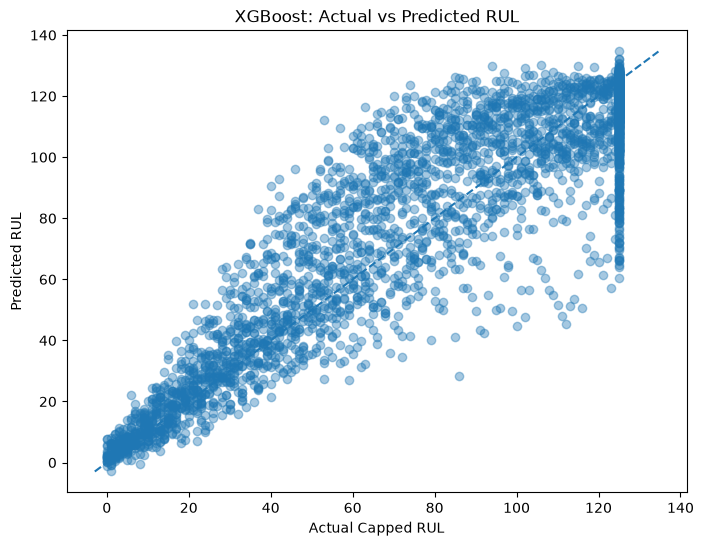

In [34]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_rul,
    xgb_pred,
    alpha=0.4
)

min_value = min(
    y_val_rul.min(),
    xgb_pred.min()
)

max_value = max(
    y_val_rul.max(),
    xgb_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Capped RUL")
plt.ylabel("Predicted RUL")
plt.title("XGBoost: Actual vs Predicted RUL")

plt.show()

Check predictions near failure
For predictive maintenance, performance near failure is especially important.
Let's evaluate observations where:
Actual RUL ≤ 30 cycles

In [35]:
near_failure_mask = (
    y_val_rul <= 30
)

near_failure_actual = (
    y_val_rul[near_failure_mask]
)

near_failure_pred = (
    xgb_pred[near_failure_mask]
)

near_failure_mae = mean_absolute_error(
    near_failure_actual,
    near_failure_pred
)

near_failure_rmse = np.sqrt(
    mean_squared_error(
        near_failure_actual,
        near_failure_pred
    )
)

print(
    "Near-failure observations:",
    len(near_failure_actual)
)

print(
    "Near-failure MAE:",
    near_failure_mae
)

print(
    "Near-failure RMSE:",
    near_failure_rmse
)

Near-failure observations: 620
Near-failure MAE: 5.558712482452393
Near-failure RMSE: 7.89796635008285


Compare RF and XGBoost near failure

In [36]:
rf_near_failure_pred = (
    rf_pred[near_failure_mask]
)

rf_near_failure_mae = mean_absolute_error(
    near_failure_actual,
    rf_near_failure_pred
)

rf_near_failure_rmse = np.sqrt(
    mean_squared_error(
        near_failure_actual,
        rf_near_failure_pred
    )
)

near_failure_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],

    "MAE (RUL <= 30)": [
        rf_near_failure_mae,
        near_failure_mae
    ],

    "RMSE (RUL <= 30)": [
        rf_near_failure_rmse,
        near_failure_rmse
    ]
})

near_failure_comparison.round(4)

,Model,MAE (RUL <= 30),RMSE (RUL <= 30)
0,Random Forest,5.9286,8.4879
1,XGBoost,5.5587,7.8980


Grouped cross-validation
Because cycles belonging to one engine must never appear in both training and validation folds

In [37]:
from sklearn.model_selection import GroupKFold

X_rul = train_df[model_features].copy()
y_rul = train_df["RUL_capped"].copy()

groups = train_df["engine_id"].copy()

group_cv = GroupKFold(n_splits=5)

print("Rows:", len(X_rul))
print("Engines:", groups.nunique())

Rows: 20631
Engines: 100


Create fresh RF and XGBoost models

In [38]:
rf_cv_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=3,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

xgb_cv_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

Evaluate both across 5 engine-grouped folds

In [39]:
def grouped_cv_evaluation(model, X, y, groups):

    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(
        group_cv.split(X, y, groups),
        start=1
    ):

        X_train_fold = X.iloc[train_idx]
        X_val_fold = X.iloc[val_idx]

        y_train_fold = y.iloc[train_idx]
        y_val_fold = y.iloc[val_idx]

        train_groups = set(groups.iloc[train_idx])
        val_groups = set(groups.iloc[val_idx])

        overlap = train_groups.intersection(val_groups)

        if len(overlap) != 0:
            raise ValueError("Engine leakage detected!")

        model.fit(
            X_train_fold,
            y_train_fold
        )

        pred = model.predict(
            X_val_fold
        )

        mae = mean_absolute_error(
            y_val_fold,
            pred
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val_fold,
                pred
            )
        )

        r2 = r2_score(
            y_val_fold,
            pred
        )

        near_mask = (
            y_val_fold.to_numpy() <= 30
        )

        near_mae = mean_absolute_error(
            y_val_fold.to_numpy()[near_mask],
            pred[near_mask]
        )

        near_rmse = np.sqrt(
            mean_squared_error(
                y_val_fold.to_numpy()[near_mask],
                pred[near_mask]
            )
        )

        fold_results.append({
            "Fold": fold,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "Near Failure MAE": near_mae,
            "Near Failure RMSE": near_rmse
        })

    return pd.DataFrame(fold_results)

Run Random Forest CV

In [40]:

rf_cv_results = grouped_cv_evaluation(
    rf_cv_model,
    X_rul,
    y_rul,
    groups
)

rf_cv_results.round(4)

,Fold,MAE,RMSE,R2,Near Failure MAE,Near Failure RMSE
0,1,12.5804,17.3307,0.8271,5.8286,8.7499
1,2,11.3386,16.2676,0.8476,6.1301,9.1183
2,3,12.0349,16.8616,0.8363,8.8735,12.4990
3,4,10.7362,15.2008,0.8670,6.8221,10.0952
4,5,11.1813,16.5140,0.8430,7.0125,10.6356


In [41]:
print("RANDOM FOREST CV MEAN")
print(rf_cv_results.mean().round(4))

print("\nRANDOM FOREST CV STD")
print(rf_cv_results.std().round(4))

RANDOM FOREST CV MEAN
Fold                  3.0000
MAE                  11.5743
RMSE                 16.4350
R2                    0.8442
Near Failure MAE      6.9334
Near Failure RMSE    10.2196
dtype: float64

RANDOM FOREST CV STD
Fold                 1.5811
MAE                  0.7309
RMSE                 0.7972
R2                   0.0149
Near Failure MAE     1.1883
Near Failure RMSE    1.4796
dtype: float64


Run XGBoost CV

In [42]:
xgb_cv_results = grouped_cv_evaluation(
    xgb_cv_model,
    X_rul,
    y_rul,
    groups
)

xgb_cv_results.round(4)

,Fold,MAE,RMSE,R2,Near Failure MAE,Near Failure RMSE
0,1,12.1957,17.1906,0.8299,5.4668,8.1088
1,2,11.2016,16.3693,0.8457,5.6253,8.6361
2,3,11.9802,17.2421,0.8288,8.1305,12.0780
3,4,10.3835,15.1477,0.8679,6.2699,9.6381
4,5,11.4587,17.4206,0.8252,6.3738,9.9353


In [43]:
print("XGBOOST CV MEAN")
print(xgb_cv_results.mean().round(4))

print("\nXGBOOST CV STD")
print(xgb_cv_results.std().round(4))

XGBOOST CV MEAN
Fold                  3.0000
MAE                  11.4440
RMSE                 16.6741
R2                    0.8395
Near Failure MAE      6.3732
Near Failure RMSE     9.6792
dtype: float64

XGBOOST CV STD
Fold                 1.5811
MAE                  0.7135
RMSE                 0.9446
R2                   0.0177
Near Failure MAE     1.0583
Near Failure RMSE    1.5310
dtype: float64


Create a clean comparison

In [44]:
cv_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],

    "MAE Mean": [
        rf_cv_results["MAE"].mean(),
        xgb_cv_results["MAE"].mean()
    ],

    "MAE Std": [
        rf_cv_results["MAE"].std(),
        xgb_cv_results["MAE"].std()
    ],

    "RMSE Mean": [
        rf_cv_results["RMSE"].mean(),
        xgb_cv_results["RMSE"].mean()
    ],

    "RMSE Std": [
        rf_cv_results["RMSE"].std(),
        xgb_cv_results["RMSE"].std()
    ],

    "R2 Mean": [
        rf_cv_results["R2"].mean(),
        xgb_cv_results["R2"].mean()
    ],

    "Near Failure MAE": [
        rf_cv_results["Near Failure MAE"].mean(),
        xgb_cv_results["Near Failure MAE"].mean()
    ],

    "Near Failure RMSE": [
        rf_cv_results["Near Failure RMSE"].mean(),
        xgb_cv_results["Near Failure RMSE"].mean()
    ]
})

cv_comparison.round(4)

,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,Near Failure MAE,Near Failure RMSE
0,Random Forest,11.5743,0.7309,16.4350,0.7972,0.8442,6.9334,10.2196
1,XGBoost,11.4440,0.7135,16.6741,0.9446,0.8395,6.3732,9.6792


The grouped CV gives us a much more reliable comparison than the earlier single split.
Metric	Random Forest	XGBoost	Better
MAE Mean ↓	11.5743	11.4440	XGBoost, slightly
MAE Std ↓	0.7309	0.7135	XGBoost
RMSE Mean ↓	16.4350	16.6741	RF, slightly
R² Mean ↑	0.8442	0.8395	RF, slightly
Near-failure MAE ↓	6.9334	6.3732	XGBoost
Near-failure RMSE ↓	10.2196	9.6792	XGBoost


The overall difference is small, but XGBoost is consistently better near failure, which is particularly relevant to predictive maintenance

Select sensors for rolling features

In [45]:
rolling_sensors = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_12",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

ROLLING_WINDOW = 5

print("Rolling sensors:", len(rolling_sensors))
print("Window:", ROLLING_WINDOW)

Rolling sensors: 10
Window: 5


Create rolling mean and standard deviation

In [46]:
rul_feature_df = train_df.copy()

for sensor in rolling_sensors:

    rul_feature_df[
        f"{sensor}_roll_mean_5"
    ] = (
        rul_feature_df
        .groupby("engine_id")[sensor]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=1
            ).mean()
        )
    )

    rul_feature_df[
        f"{sensor}_roll_std_5"
    ] = (
        rul_feature_df
        .groupby("engine_id")[sensor]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=2
            ).std()
        )
    )

In [47]:
rolling_std_columns = [
    f"{sensor}_roll_std_5"
    for sensor in rolling_sensors
]

rul_feature_df[
    rolling_std_columns
] = rul_feature_df[
    rolling_std_columns
].fillna(0)

In [48]:
print(
    "Missing values:",
    rul_feature_df.isnull().sum().sum()
)

Missing values: 0


Create final feature list

In [49]:
rolling_features = []

for sensor in rolling_sensors:

    rolling_features.extend([
        f"{sensor}_roll_mean_5",
        f"{sensor}_roll_std_5"
    ])

enhanced_features = (
    model_features
    + rolling_features
)

print("Original features:", len(model_features))
print("Rolling features :", len(rolling_features))
print("Total features   :", len(enhanced_features))

Original features: 18
Rolling features : 20
Total features   : 38


Prepare enhanced dataset

In [50]:
X_enhanced = (
    rul_feature_df[
        enhanced_features
    ].copy()
)

y_enhanced = (
    rul_feature_df[
        "RUL_capped"
    ].copy()
)

enhanced_groups = (
    rul_feature_df[
        "engine_id"
    ].copy()
)

print("X:", X_enhanced.shape)
print("y:", y_enhanced.shape)
print(
    "Engines:",
    enhanced_groups.nunique()
)

X: (20631, 38)
y: (20631,)
Engines: 100


Test enhanced XGBoost using same grouped CV

In [51]:
xgb_enhanced = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_enhanced_results = grouped_cv_evaluation(
    xgb_enhanced,
    X_enhanced,
    y_enhanced,
    enhanced_groups
)

xgb_enhanced_results.round(4)

,Fold,MAE,RMSE,R2,Near Failure MAE,Near Failure RMSE
0,1,12.0485,16.9224,0.8351,5.0118,7.4101
1,2,11.1486,16.2557,0.8478,5.1045,8.3271
2,3,11.6310,16.6738,0.8399,7.8722,11.6812
3,4,10.1257,14.9338,0.8716,5.8926,9.1084
4,5,11.4053,17.4546,0.8246,6.1133,10.0020


Compare original vs enhanced XGBoost

In [52]:
rolling_comparison = pd.DataFrame({
    "Model": [
        "XGBoost - Current Sensors",
        "XGBoost - Current + Rolling"
    ],

    "MAE Mean": [
        xgb_cv_results["MAE"].mean(),
        xgb_enhanced_results["MAE"].mean()
    ],

    "MAE Std": [
        xgb_cv_results["MAE"].std(),
        xgb_enhanced_results["MAE"].std()
    ],

    "RMSE Mean": [
        xgb_cv_results["RMSE"].mean(),
        xgb_enhanced_results["RMSE"].mean()
    ],

    "R2 Mean": [
        xgb_cv_results["R2"].mean(),
        xgb_enhanced_results["R2"].mean()
    ],

    "Near Failure MAE": [
        xgb_cv_results["Near Failure MAE"].mean(),
        xgb_enhanced_results["Near Failure MAE"].mean()
    ],

    "Near Failure RMSE": [
        xgb_cv_results["Near Failure RMSE"].mean(),
        xgb_enhanced_results["Near Failure RMSE"].mean()
    ]
})

rolling_comparison.round(4)

,Model,MAE Mean,MAE Std,RMSE Mean,R2 Mean,Near Failure MAE,Near Failure RMSE
0,XGBoost - Current Sensors,11.4440,0.7135,16.6741,0.8395,6.3732,9.6792
1,XGBoost - Current + Rolling,11.2718,0.7209,16.4481,0.8438,5.9989,9.3058


The gain is modest, but because it is consistent, keep the rolling features. Now we should tune the enhanced XGBoost model using grouped CV

Tune XGBoost

In [53]:
from sklearn.model_selection import RandomizedSearchCV

xgb_tuning_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_distributions = {
    "n_estimators": [300, 500, 700, 900],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "max_depth": [3, 4, 5, 6],
    "min_child_weight": [1, 3, 5, 7],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "reg_alpha": [0, 0.1, 0.5, 1.0],
    "reg_lambda": [0.5, 1.0, 2.0, 5.0]
}

Randomized search with engine groups

In [54]:
random_search = RandomizedSearchCV(
    estimator=xgb_tuning_model,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=group_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(
    X_enhanced,
    y_enhanced,
    groups=enhanced_groups
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.02, 0.03, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a be

See the best parameters

In [55]:
print("Best CV RMSE:")
print(-random_search.best_score_)

print("\nBest Parameters:")

for parameter, value in random_search.best_params_.items():
    print(parameter, ":", value)

Best CV RMSE:
16.297207832336426

Best Parameters:
subsample : 0.8
reg_lambda : 1.0
reg_alpha : 0.5
n_estimators : 300
min_child_weight : 7
max_depth : 5
learning_rate : 0.03
colsample_bytree : 1.0


In [56]:
best_xgb_rul = random_search.best_estimator_

tuned_xgb_results = grouped_cv_evaluation(
    best_xgb_rul,
    X_enhanced,
    y_enhanced,
    enhanced_groups
)

tuned_xgb_results.round(4)

,Fold,MAE,RMSE,R2,Near Failure MAE,Near Failure RMSE
0,1,11.8476,16.7508,0.8385,4.8333,7.3469
1,2,11.0034,16.0989,0.8507,5.2541,8.2859
2,3,11.3802,16.5022,0.8432,7.7853,11.7430
3,4,10.0174,14.8374,0.8732,5.6944,8.8061
4,5,11.3196,17.3834,0.8260,6.0740,10.0125


In [57]:
tuned_summary = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R2",
        "Near Failure MAE",
        "Near Failure RMSE"
    ],

    "Untuned XGBoost": [
        xgb_enhanced_results["MAE"].mean(),
        xgb_enhanced_results["RMSE"].mean(),
        xgb_enhanced_results["R2"].mean(),
        xgb_enhanced_results["Near Failure MAE"].mean(),
        xgb_enhanced_results["Near Failure RMSE"].mean()
    ],

    "Tuned XGBoost": [
        tuned_xgb_results["MAE"].mean(),
        tuned_xgb_results["RMSE"].mean(),
        tuned_xgb_results["R2"].mean(),
        tuned_xgb_results["Near Failure MAE"].mean(),
        tuned_xgb_results["Near Failure RMSE"].mean()
    ]
})

tuned_summary.round(4)

,Metric,Untuned XGBoost,Tuned XGBoost
0,MAE,11.2718,11.1136
1,RMSE,16.4481,16.3146
2,R2,0.8438,0.8463
3,Near Failure MAE,5.9989,5.9282
4,Near Failure RMSE,9.3058,9.2389


Tuning improved all five metrics, so the tuned XGBoost is our preferred RUL development model.

Train tuned model on all training engines

In [58]:
best_xgb_rul.fit(
    X_enhanced,
    y_enhanced
)

print("Final RUL model trained on all training engines!")

Final RUL model trained on all training engines!


Create rolling features for NASA test data

In [59]:
test_feature_df = test_df.copy()

for sensor in rolling_sensors:

    test_feature_df[
        f"{sensor}_roll_mean_5"
    ] = (
        test_feature_df
        .groupby("engine_id")[sensor]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=1
            ).mean()
        )
    )

    test_feature_df[
        f"{sensor}_roll_std_5"
    ] = (
        test_feature_df
        .groupby("engine_id")[sensor]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=2
            ).std()
        )
    )

test_feature_df[
    rolling_std_columns
] = test_feature_df[
    rolling_std_columns
].fillna(0)

print(
    "Missing values:",
    test_feature_df[enhanced_features]
    .isnull()
    .sum()
    .sum()
)

print(
    "Test engines:",
    test_feature_df["engine_id"].nunique()
)

Missing values: 0
Test engines: 100


Select each engine's last observed cycle

In [60]:
test_last = (
    test_feature_df
    .sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)

print("Rows selected:", len(test_last))

test_last[
    ["engine_id", "cycle"]
].head(10)

Rows selected: 100


,engine_id,cycle
0,1,31
1,2,49
2,3,126
3,4,106
4,5,98
5,6,105
6,7,160
7,8,166
8,9,55
9,10,192


Prepare official NASA targets

In [61]:
print("Test engines:", len(test_last))
print("RUL labels :", len(rul_df))

Test engines: 100
RUL labels : 100


remember: our model was trained using:
RUL_capped = min(RUL, 125)

Therefore, for an apples-to-apples evaluation of this capped-target model, create the corresponding capped test target:

In [62]:
y_test_nasa_original = (
    rul_df["RUL"]
    .to_numpy()
)

y_test_nasa_capped = np.minimum(
    y_test_nasa_original,
    RUL_CAP
)

print(
    "Original NASA RUL range:",
    y_test_nasa_original.min(),
    "to",
    y_test_nasa_original.max()
)

print(
    "Capped evaluation range:",
    y_test_nasa_capped.min(),
    "to",
    y_test_nasa_capped.max()
)

Original NASA RUL range: 7 to 145
Capped evaluation range: 7 to 125


Generate predictions

In [63]:
X_test_nasa = test_last[
    enhanced_features
].copy()

nasa_predictions = best_xgb_rul.predict(
    X_test_nasa
)

# RUL cannot physically be negative
nasa_predictions = np.maximum(
    nasa_predictions,
    0
)

print("Predictions:", len(nasa_predictions))
print(nasa_predictions[:10])

Predictions: 100
[123.56227  119.63092   52.130962  73.9942    97.31966   90.579834
 102.686386  76.88602  119.155426  96.85676 ]


Final capped-target metric

In [64]:
nasa_mae = mean_absolute_error(
    y_test_nasa_capped,
    nasa_predictions
)

nasa_rmse = np.sqrt(
    mean_squared_error(
        y_test_nasa_capped,
        nasa_predictions
    )
)

nasa_r2 = r2_score(
    y_test_nasa_capped,
    nasa_predictions
)

print("NASA FD001 FINAL TEST — CAPPED TARGET")
print("-------------------------------------")
print("MAE :", nasa_mae)
print("RMSE:", nasa_rmse)
print("R2  :", nasa_r2)

NASA FD001 FINAL TEST — CAPPED TARGET
-------------------------------------
MAE : 12.858792304992676
RMSE: 17.68970748012589
R2  : 0.80513596534729


Also evaluate against original NASA RUL

In [65]:
original_mae = mean_absolute_error(
    y_test_nasa_original,
    nasa_predictions
)

original_rmse = np.sqrt(
    mean_squared_error(
        y_test_nasa_original,
        nasa_predictions
    )
)

original_r2 = r2_score(
    y_test_nasa_original,
    nasa_predictions
)

print("NASA FD001 TEST — ORIGINAL RUL")
print("--------------------------------")
print("MAE :", original_mae)
print("RMSE:", original_rmse)
print("R2  :", original_r2)

NASA FD001 TEST — ORIGINAL RUL
--------------------------------
MAE : 13.928792953491211
RMSE: 18.88523819494177
R2  : 0.7934689521789551


Near-failure external performance
Now check test engines whose original NASA RUL ≤ 30:

In [66]:
near_failure_test_mask = (
    y_test_nasa_original <= 30
)

print(
    "Near-failure test engines:",
    near_failure_test_mask.sum()
)

if near_failure_test_mask.sum() > 0:

    nasa_near_mae = mean_absolute_error(
        y_test_nasa_original[
            near_failure_test_mask
        ],
        nasa_predictions[
            near_failure_test_mask
        ]
    )

    nasa_near_rmse = np.sqrt(
        mean_squared_error(
            y_test_nasa_original[
                near_failure_test_mask
            ],
            nasa_predictions[
                near_failure_test_mask
            ]
        )
    )

    print(
        "Near-failure MAE:",
        nasa_near_mae
    )

    print(
        "Near-failure RMSE:",
        nasa_near_rmse
    )

Near-failure test engines: 25
Near-failure MAE: 8.61988353729248
Near-failure RMSE: 14.532406602996101


Inspect actual vs predicted

In [67]:
final_predictions_df = pd.DataFrame({
    "Engine ID": test_last["engine_id"],
    "Last Observed Cycle": test_last["cycle"],
    "Actual RUL": y_test_nasa_original,
    "Actual Capped RUL": y_test_nasa_capped,
    "Predicted RUL": nasa_predictions
})

final_predictions_df["Absolute Error"] = (
    final_predictions_df["Actual Capped RUL"]
    - final_predictions_df["Predicted RUL"]
).abs()

final_predictions_df.head(20).round(2)

,Engine ID,Last Observed Cycle,Actual RUL,Actual Capped RUL,Predicted RUL,Absolute Error
0,1,31,112,112,123.559998,11.56
1,2,49,98,98,119.629997,21.63
2,3,126,69,69,52.130001,16.87
3,4,106,82,82,73.989998,8.01
4,5,98,91,91,97.320000,6.32
5,6,105,93,93,90.580002,2.42
6,7,160,91,91,102.690002,11.69
7,8,166,95,95,76.889999,18.11
8,9,55,111,111,119.160004,8.16
9,10,192,96,96,96.860001,0.86


Then inspect the worst cases:

In [68]:
final_predictions_df.sort_values(
    "Absolute Error",
    ascending=False
).head(10).round(2)

,Engine ID,Last Observed Cycle,Actual RUL,Actual Capped RUL,Predicted RUL,Absolute Error
44,45,152,114,114,61.369999,52.63
73,74,137,126,125,74.209999,50.79
36,37,121,21,21,63.270000,42.27
92,93,244,85,85,46.400002,38.60
29,30,143,115,115,77.110001,37.89
88,89,177,136,125,87.430000,37.57
66,67,71,77,77,114.540001,37.54
40,41,123,18,18,53.650002,35.65
17,18,133,28,28,63.500000,35.50
50,51,144,114,114,79.029999,34.97


Save the final RUL model

In [69]:
import joblib

joblib.dump(
    best_xgb_rul,
    "../models/rul_xgboost.joblib"
)

print("Final RUL model saved!")

Final RUL model saved!
